# 대륙별 멸종위기종(CR) EDA 리포트 🐯

> **분석 질문**: 대륙별로 어떤 분류군의 CR(위급) 비중이 가장 높을까?

**목차**
1. 데이터 수집 (위키데이터)
2. 데이터 정제하기
3. 데이터 시각화
4. 통합 리포트 (결과 · 한계점 · 결론)
5. (선택) IUCN 적색목록 API로 다시 수집하기

## 1. 데이터 수집 (위키데이터)
위키데이터에서 '대륙별 · 분류군별 IUCN 멸종위기 등급' 데이터를 수집하는 스크립트

수집 대상: IUCN 등급(P141)과 고유 분포 국가(P183, endemic to)가 모두 기록된 종
결과 파일:
  - 멸종위기_종별_대륙.csv : 종 × 대륙 (한 종이 여러 대륙에 걸치면 대륙마다 1행)

출처연도: IUCN 등급의 출처인 'IUCN 적색목록 버전'의 발행 연도(없으면 위키데이터 조회 연도).
실제 IUCN 평가 연도와는 다를 수 있다. 최근 10년 이내 출처만 남긴다.

실행: 위에서부터 셀을 차례로 실행 (약 3~5분 소요)
필요 패키지: requests, pandas

In [ ]:
import io
import time
from pathlib import Path

import pandas as pd
import requests

SPARQL_URL = "https://query.wikidata.org/sparql"
HEADERS = {"User-Agent": "DI2-EDA-student/1.0", "Accept": "text/csv"}
OUT_DIR = Path.cwd()  # 노트북이 있는 폴더에 저장
BATCH = 400  # 한 번의 쿼리에 넣을 ID 개수

In [ ]:
# ── 1-1. 공통 함수 ─────────────────────────────────────────────
def sparql(query, retries=4):
    """SPARQL 쿼리를 보내고 결과를 DataFrame으로 받는다. 실패하면 몇 번 재시도."""
    for i in range(retries):
        try:
            res = requests.post(SPARQL_URL, data={"query": query}, headers=HEADERS, timeout=120)
            res.raise_for_status()
            return pd.read_csv(io.StringIO(res.text), dtype=str)
        except requests.RequestException as e:
            print(f"  재시도 {i + 1}/{retries}: {e}")
            time.sleep(5)
    raise RuntimeError("SPARQL 요청 실패")


def to_qid(series):
    """'http://www.wikidata.org/entity/Q123' → 'Q123'"""
    return series.str.rsplit("/", n=1).str[-1]


def values_clause(ids):
    return " ".join("wd:" + x for x in ids)

In [ ]:
# ── 1-2. 종 · IUCN 등급 · 출처 연도 · 대륙 수집 ────────────────
# 위키데이터에는 종의 대륙 정보가 없어서, 고유 분포 국가(P183) → 대륙(P30) 순으로 찾아간다.
# 국가는 쿼리 안에서만 거쳐 가고 결과에는 대륙만 받는다.
# 출처 연도: IUCN 등급의 출처(IUCN 적색목록 버전)의 발행 연도, 없으면 조회 연도
print("1) 종 목록 수집 중...")
base = sparql("""
SELECT ?sp ?sciname ?status ?rank ?cont (MAX(?yr) AS ?year) WHERE {
  ?sp p:P141 ?st ;                     # IUCN 보전 상태 (문장 단위)
      wdt:P183/wdt:P30 ?cont .         # 고유 분포 국가가 속한 대륙
  ?st ps:P141 ?status ; wikibase:rank ?rank .
  FILTER(?rank != wikibase:DeprecatedRank)   # 폐기된 기록 제외
  OPTIONAL { ?sp wdt:P225 ?sciname }   # 학명
  OPTIONAL { ?st prov:wasDerivedFrom ?ref .
             OPTIONAL { ?ref pr:P248/wdt:P577 ?pub }   # 출처 발행일
             OPTIONAL { ?ref pr:P813 ?ret } }          # 조회일
  BIND(COALESCE(YEAR(?pub), YEAR(?ret)) AS ?yr)
} GROUP BY ?sp ?sciname ?status ?rank ?cont""")
for col in ["sp", "status", "cont"]:
    base[col] = to_qid(base[col])
base["year"] = pd.to_numeric(base["year"])

# 한 종에 등급 기록이 여러 개면 '우선(preferred)' 기록 → 최신 연도 순으로 1개만 남긴다
base["preferred"] = base["rank"].str.endswith("PreferredRank")
base = (base.sort_values(["preferred", "year"], ascending=False)
            .drop_duplicates(["sp", "cont"])
            .drop(columns=["rank", "preferred"]))
print(f"   {len(base)}행, 고유종 {base.sp.nunique()}종")

1) 종 목록 수집 중...
   8703행, 고유종 8635종


In [ ]:
# ── 1-3. 상위 분류군 따라 올라가기 ──────────────────────────────
# P171* 같은 경로 쿼리는 시간 초과가 나기 쉬워서,
# 부모 분류군(P171)을 한 단계씩 조회하며 위로 올라간다.
print("2) 분류 체계 수집 중...")
taxo = {}  # {QID: (부모 QID 리스트, 학명)}
frontier = set(base.sp)
step = 0
while frontier:
    todo = [x for x in frontier if x not in taxo]
    if not todo:
        break
    for i in range(0, len(todo), BATCH):
        r = sparql(f"""
        SELECT ?n ?p ?name WHERE {{
          VALUES ?n {{ {values_clause(todo[i:i + BATCH])} }}
          OPTIONAL {{ ?n wdt:P171 ?p }}
          OPTIONAL {{ ?n wdt:P225 ?name }}
        }}""")
        r["n"], r["p"] = to_qid(r["n"]), to_qid(r["p"])
        for n, g in r.groupby("n"):
            names = g["name"].dropna()
            taxo[n] = (sorted(g["p"].dropna().unique()), names.iloc[0] if len(names) else None)
    frontier = {p for n in todo for p in taxo.get(n, ([], None))[0]}
    step += 1
    print(f"   {step}단계: {len(todo)}개 조회, 다음 {len(frontier)}개")


def lineage(qid):
    """종에서 최상위까지의 분류군 학명 리스트"""
    names, seen = [], set()
    while qid and qid not in seen:
        seen.add(qid)
        parents, name = taxo.get(qid, ([], None))
        if name:
            names.append(name)
        qid = parents[0] if parents else None
    return names


# 분류 단계에 아래 학명이 있으면 해당 그룹으로 분류 (위에 있을수록 우선)
GROUPS = [
    ("Mammalia", "포유류"), ("Aves", "조류"),
    ("Reptilia", "파충류"), ("Squamata", "파충류"), ("Testudines", "파충류"), ("Crocodylia", "파충류"),
    ("Amphibia", "양서류"),
    ("Actinopterygii", "어류"), ("Teleostei", "어류"), ("Chondrichthyes", "어류"), ("Myxini", "어류"),
    ("Petromyzontida", "어류"), ("Sarcopterygii", "어류"), ("Holocephali", "어류"),
    ("Insecta", "곤충"), ("Arachnida", "거미류"),
    ("Crustacea", "갑각류"), ("Malacostraca", "갑각류"), ("Copepoda", "갑각류"),
    ("Mollusca", "연체동물"), ("Annelida", "환형동물"), ("Cnidaria", "자포동물"),
    ("Angiosperms", "식물"), ("Magnoliophyta", "식물"), ("Spermatophytes", "식물"),
    ("Tracheophyta", "식물"), ("Tracheophytes", "식물"), ("Embryophyta", "식물"), ("Plantae", "식물"),
    ("Fungi", "균류"),
]


def taxon_group(qid):
    names = set(lineage(qid))
    for key, group in GROUPS:
        if key in names:
            return group
    return "기타"


base["group"] = base.sp.map({sp: taxon_group(sp) for sp in base.sp.unique()})

2) 분류 체계 수집 중...
   1단계: 8635개 조회, 다음 2706개
   2단계: 2701개 조회, 다음 1209개
   3단계: 1182개 조회, 다음 726개
   4단계: 580개 조회, 다음 443개
   5단계: 296개 조회, 다음 270개
   6단계: 158개 조회, 다음 169개
   7단계: 96개 조회, 다음 106개
   8단계: 60개 조회, 다음 66개
   9단계: 43개 조회, 다음 44개
   10단계: 19개 조회, 다음 18개
   11단계: 11개 조회, 다음 15개
   12단계: 11개 조회, 다음 12개
   13단계: 9개 조회, 다음 11개
   14단계: 7개 조회, 다음 10개
   15단계: 7개 조회, 다음 10개
   16단계: 3개 조회, 다음 3개
   17단계: 3개 조회, 다음 3개
   18단계: 3개 조회, 다음 3개
   19단계: 3개 조회, 다음 3개
   20단계: 3개 조회, 다음 3개
   21단계: 3개 조회, 다음 3개
   22단계: 3개 조회, 다음 4개
   23단계: 3개 조회, 다음 3개
   24단계: 1개 조회, 다음 1개
   25단계: 1개 조회, 다음 1개
   26단계: 1개 조회, 다음 1개
   27단계: 1개 조회, 다음 2개
   28단계: 2개 조회, 다음 2개
   29단계: 1개 조회, 다음 1개
   30단계: 1개 조회, 다음 1개
   31단계: 1개 조회, 다음 1개
   32단계: 1개 조회, 다음 1개
   33단계: 1개 조회, 다음 1개
   34단계: 1개 조회, 다음 1개


In [ ]:
# ── 1-4. 이름(한글/영어) 붙이기 ────────────────────────────────
print("3) 이름 수집 중...")
ids = sorted(set(base.sp) | set(base.status) | set(base.cont))
labels = []
for i in range(0, len(ids), BATCH):
    labels.append(sparql(f"""
    SELECT ?e ?en ?ko WHERE {{
      VALUES ?e {{ {values_clause(ids[i:i + BATCH])} }}
      OPTIONAL {{ ?e rdfs:label ?en FILTER(lang(?en) = "en") }}
      OPTIONAL {{ ?e rdfs:label ?ko FILTER(lang(?ko) = "ko") }}
    }}"""))
labels = pd.concat(labels)
labels["e"] = to_qid(labels["e"])
labels = labels.drop_duplicates("e").set_index("e")
en, ko = labels["en"], labels["ko"]

3) 이름 수집 중...


In [ ]:
# ── 1-5. 정리 후 저장 ──────────────────────────────────────────
IUCN_CODE = {
    "critically endangered": "CR", "endangered": "EN", "vulnerable": "VU",
    "near threatened": "NT", "least concern": "LC", "Data Deficient": "DD",
    "extinct": "EX", "extinct in the wild": "EW",
}
CONTINENT = {
    "Asia": "아시아", "Africa": "아프리카", "Europe": "유럽",
    "North America": "북아메리카", "South America": "남아메리카", "Antarctica": "남극",
    "Oceania": "오세아니아", "Insular Oceania": "오세아니아", "Australian continent": "오세아니아",
    # "Americas", "Eurasia"처럼 대륙이 애매한 값은 매핑하지 않음 → 제외
}
MIN_YEAR = pd.Timestamp.now().year - 10  # 최근 10년 이내 출처만 사용

df = pd.DataFrame({
    "wikidata_id": base.sp,
    "학명": base.sciname,
    "이름": base.sp.map(ko).fillna(base.sp.map(en)),
    "분류군": base.group,
    "IUCN등급": base.status.map(en).map(IUCN_CODE),
    "출처연도": base.year.astype("Int64"),
    "대륙": base.cont.map(en).map(CONTINENT),
})
print(f"   대륙이 애매해서 제외한 행: {df['대륙'].isna().sum()}")
df = df.dropna(subset=["대륙"])

old = ~(df["출처연도"] >= MIN_YEAR).fillna(False)
print(f"   출처연도가 {MIN_YEAR}년 미만이거나 없어서 제외한 행: {old.sum()}")
df = df[~old]

# 오세아니아처럼 여러 값을 하나로 합친 대륙은 중복이 생길 수 있어 한 종당 1행으로 정리
df = df.sort_values("출처연도", ascending=False).drop_duplicates(["wikidata_id", "대륙"])

df.to_csv(OUT_DIR / "멸종위기_종별_대륙.csv", index=False, encoding="utf-8-sig")
print(f"완료! 종×대륙 {len(df)}행 저장 → {OUT_DIR}")

   대륙이 애매해서 제외한 행: 8
   출처연도가 2016년 미만이거나 없어서 제외한 행: 40
완료! 종×대륙 8614행 저장 → c:\Users\sypar\OneDrive\바탕 화면\DI-2\웹스크래핑


## 2. 데이터 정제하기

In [3]:
# ── 2-1. 데이터 불러오기 · 중복 제거 ─────────────────────────
# 수집 셀을 다시 돌리지 않아도 되도록, 정제에 필요한 것만 여기서 다시 준비한다
import io
import time
from pathlib import Path

import pandas as pd
import requests


def sparql(query, retries=4):
    """위키데이터 SPARQL 조회 (실패하면 재시도)"""
    for i in range(retries):
        try:
            res = requests.post("https://query.wikidata.org/sparql", data={"query": query},
                                headers={"User-Agent": "DI2-EDA-student/1.0", "Accept": "text/csv"}, timeout=120)
            res.raise_for_status()
            return pd.read_csv(io.StringIO(res.text), dtype=str)
        except requests.RequestException as e:
            print(f"  재시도 {i + 1}/{retries}: {e}")
            time.sleep(5)
    raise RuntimeError("SPARQL 요청 실패")


def to_qid(series):
    return series.str.rsplit("/", n=1).str[-1]


CONTINENT = {
    "Asia": "아시아", "Africa": "아프리카", "Europe": "유럽",
    "North America": "북아메리카", "South America": "남아메리카", "Antarctica": "남극",
    "Oceania": "오세아니아", "Insular Oceania": "오세아니아", "Australian continent": "오세아니아",
}

raw = pd.read_csv(Path.cwd() / "멸종위기_종별_대륙.csv")
print(f"불러온 데이터: {raw.shape}")
display(raw.head())

clean = raw.drop_duplicates()
print(f"완전히 같은 행: {len(raw) - len(clean)}개 제거")

# 같은 종 · 같은 대륙인데 다른 값(등급, 연도 등)이 들어간 행 → 최신 출처 1개만 남김
dup = clean.duplicated(["wikidata_id", "대륙"], keep=False)
print(f"같은 종 · 같은 대륙인데 값이 다른 행: {dup.sum()}개")
clean = clean.sort_values("출처연도", ascending=False).drop_duplicates(["wikidata_id", "대륙"])
print(f"중복 제거 후 {len(clean)}행")

불러온 데이터: (8614, 7)


,wikidata_id,학명,이름,분류군,IUCN등급,출처연도,대륙
0,Q3850927,Pseudopanax lessonii,Pseudopanax lessonii,식물,LC,2026,오세아니아
1,Q2662709,Brachychiton rupestris,Brachychiton rupestris,식물,LC,2026,오세아니아
2,Q18479513,Fritziana ulei,Fritziana ulei,양서류,LC,2026,남아메리카
3,Q457872,Macrochelys temminckii,악어거북,파충류,EN,2025,북아메리카
4,Q131736602,Dryophylax almae,Dryophylax almae,파충류,LC,2025,남아메리카


완전히 같은 행: 0개 제거
같은 종 · 같은 대륙인데 값이 다른 행: 0개
중복 제거 후 8614행


In [4]:
# ── 2-2. 여러 대륙에 걸친 종 → 대륙 1개로 정리 ──────────────
multi = clean[clean["wikidata_id"].duplicated(keep=False)]
print(f"여러 대륙에 걸친 종: {multi['wikidata_id'].nunique()}종")
display(multi.groupby(["wikidata_id", "학명"])["대륙"].agg(" + ".join).reset_index())

# 위키데이터에서 모식 산지(P5304, 처음 기재된 표본의 채집지)와 고유 분포 국가(P183)를 조회
v = " ".join("wd:" + x for x in multi["wikidata_id"].unique())
loc = sparql(f"""
SELECT ?sp ?how ?c ?contLabel WHERE {{
  VALUES ?sp {{ {v} }}
  {{ ?sp wdt:P5304 ?tl . ?tl wdt:P17 ?c . ?c wdt:P30 ?cont . BIND("모식산지" AS ?how) }}
  UNION
  {{ ?sp wdt:P183 ?c . ?c wdt:P30 ?cont . BIND("분포국가" AS ?how) }}
  SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
}}""")
loc["sp"] = to_qid(loc["sp"])
loc["대륙"] = loc["contLabel"].map(CONTINENT)
print(f"모식 산지가 기록된 종: {loc.loc[loc['how'] == '모식산지', 'sp'].nunique()}종")

# 대륙에 걸쳐 있는 나라 때문에 생긴 경우의 규칙 (해당 종들의 실제 서식지 기준)
PAIR_RULE = {
    frozenset({"아시아", "유럽"}): "아시아",     # 튀르키예(아나톨리아) · 키프로스 · 러시아(시베리아) 등
    frozenset({"남극", "아프리카"}): "아프리카",  # 프랑스령 남방 지역: 인도양 섬들
    frozenset({"아프리카", "유럽"}): "아프리카",  # 마카로네시아(카나리아 제도 등): 아프리카 연안 섬
}


def pick_continent(sp, conts):
    """모식 산지 → 대륙 걸침 규칙 → 분포 국가가 더 많은 대륙 순으로 대륙 1개를 고른다"""
    tl = loc[(loc["sp"] == sp) & (loc["how"] == "모식산지")]["대륙"].dropna()
    if tl.nunique() == 1 and tl.iloc[0] in conts:
        return tl.iloc[0], "모식 산지"
    if frozenset(conts) in PAIR_RULE:
        return PAIR_RULE[frozenset(conts)], "대륙 걸침 국가 규칙"
    dist = loc[(loc["sp"] == sp) & (loc["how"] == "분포국가") & loc["대륙"].isin(conts)]
    top = dist.groupby("대륙")["c"].nunique().sort_values(ascending=False)
    return top.index[0], f"분포 국가 수 {top.to_dict()}"


decision = pd.DataFrame(
    [(sp, g["학명"].iloc[0], *pick_continent(sp, set(g["대륙"]))) for sp, g in multi.groupby("wikidata_id")],
    columns=["wikidata_id", "학명", "결정대륙", "근거"],
).set_index("wikidata_id")
display(decision)

keep = clean["wikidata_id"].map(decision["결정대륙"])
clean = clean[keep.isna() | (clean["대륙"] == keep)]
print(f"정리 후 {len(clean)}행, 여러 대륙에 걸친 종: {clean['wikidata_id'].duplicated().sum()}종")

여러 대륙에 걸친 종: 22종


,wikidata_id,학명,대륙
0,Q108866108,Bufotes cypriensis,아시아 + 유럽
1,Q1193791,Quercus alnifolia,아시아 + 유럽
2,Q15579172,Ferula mervynii,아시아 + 유럽
3,Q1766281,Dryomys laniger,아시아 + 유럽
4,Q1969787,Vipera lotievi,아시아 + 유럽
5,Q2047840,Hippocampus histrix,오세아니아 + 아시아
6,Q21949185,Leucogeranus leucogeranus,유럽 + 아시아
7,Q22704092,Fringilla polatzeki,유럽 + 아프리카
8,Q240962,Diomedea amsterdamensis,아프리카 + 남극
9,Q244011,Hippocampus bargibanti,아시아 + 오세아니아


모식 산지가 기록된 종: 0종


,학명,결정대륙,근거
wikidata_id,,,
Q108866108,Bufotes cypriensis,아시아,대륙 걸침 국가 규칙
Q1193791,Quercus alnifolia,아시아,대륙 걸침 국가 규칙
Q15579172,Ferula mervynii,아시아,대륙 걸침 국가 규칙
Q1766281,Dryomys laniger,아시아,대륙 걸침 국가 규칙
Q1969787,Vipera lotievi,아시아,대륙 걸침 국가 규칙
Q2047840,Hippocampus histrix,아시아,"분포 국가 수 {'아시아': 2, '오세아니아': 1}"
Q21949185,Leucogeranus leucogeranus,아시아,대륙 걸침 국가 규칙
Q22704092,Fringilla polatzeki,아프리카,대륙 걸침 국가 규칙
Q240962,Diomedea amsterdamensis,아프리카,대륙 걸침 국가 규칙


정리 후 8592행, 여러 대륙에 걸친 종: 0종


In [5]:
# ── 2-3. 동물종만 남기기 ─────────────────────────────────────
NON_ANIMAL = ["식물", "균류"]
print(clean["분류군"].value_counts())

# '기타'는 노래기 · 유조동물(벨벳웜) · 끈벌레 · 요정새우 등 → 모두 동물이라 남긴다
display(clean[clean["분류군"] == "기타"][["학명", "이름"]])

animal = clean[~clean["분류군"].isin(NON_ANIMAL)].copy()
animal["분류군"] = animal["분류군"].replace({"기타": "기타 무척추동물"})
print(f"동물종만 남김: {len(clean)}행 → {len(animal)}행")

분류군
파충류     2747
양서류     2112
조류      1237
식물      1138
포유류      650
어류       224
곤충       154
연체동물     112
환형동물      94
갑각류       75
거미류       25
균류        19
기타         5
Name: count, dtype: int64


,학명,이름
949,Aphistogoniulus corallipes,Aphistogoniulus corallipes
3993,Peripatoides indigo,Peripatoides indigo
5671,Antiponemertes allisonae,Antiponemertes allisonae
6161,Peripatoides suteri,Peripatoides suteri
6307,Linderiella baetica,Linderiella baetica


동물종만 남김: 8592행 → 7435행


In [6]:
# ── 2-4-1. 같은 종인데 표기가 다른 경우 확인 ─────────────────
# (1) 공백 · 유니코드 정리: 앞뒤 공백, 두 칸 이상 공백, 같은 글자인데 코드가 다른 경우(ë 등)
for col in ["학명", "이름"]:
    before = animal[col].copy()
    animal[col] = animal[col].str.normalize("NFC").str.strip().str.replace(r"\s+", " ", regex=True)
    print(f"{col}: 공백·유니코드 정리 {(before.fillna('') != animal[col].fillna('')).sum()}건")

# (2) 학명 · 이름 빈칸은 서로의 값으로 채움 (위키데이터에서 이름 칸에 학명이 들어간 경우가 있음)
print(f"학명 없음 → 이름으로 채움: {animal['학명'].isna().sum()}건 / "
      f"이름 없음 → 학명으로 채움: {animal['이름'].isna().sum()}건")
display(animal[animal["학명"].isna() | animal["이름"].isna()])
animal["학명"] = animal["학명"].fillna(animal["이름"])
animal["이름"] = animal["이름"].fillna(animal["학명"])

# (3) 대소문자만 다른 학명 (예: 'Panthera Tigris' vs 'Panthera tigris')
lower = animal["학명"].str.lower()
case_dup = animal[lower.duplicated(keep=False) & ~animal["학명"].duplicated(keep=False)]
print(f"대소문자만 다른 학명: {len(case_dup)}건")
# 학명 규칙(속명만 대문자로 시작)에 맞지 않는 표기
odd = animal[~animal["학명"].str.match(r"^[A-Z][a-z\-]+( [a-z\-]+)*$")]
print(f"학명 규칙에 맞지 않는 표기: {len(odd)}건")
display(odd[["wikidata_id", "학명", "이름"]])

# (4) 학명은 다른데 이름(한글/영어)이 같은 경우 → 같은 종의 다른 표기일 수 있어 눈으로 확인
same_name = animal[animal.duplicated(["이름", "대륙"], keep=False) & (animal["이름"] != animal["학명"])]
print(f"이름은 같은데 학명이 다른 행: {len(same_name)}건")
display(same_name.sort_values("이름")[["wikidata_id", "학명", "이름", "IUCN등급", "대륙"]])

학명: 공백·유니코드 정리 1건
이름: 공백·유니코드 정리 0건
학명 없음 → 이름으로 채움: 1건 / 이름 없음 → 학명으로 채움: 1건


,wikidata_id,학명,이름,분류군,IUCN등급,출처연도,대륙
3264,Q21301567,NaN,Pontodrilus lacustris,환형동물,LC,2022,오세아니아
6714,Q19683980,Pristimantis mutabilis,NaN,양서류,EN,2022,남아메리카


대소문자만 다른 학명: 0건
학명 규칙에 맞지 않는 표기: 0건


,wikidata_id,학명,이름


이름은 같은데 학명이 다른 행: 0건


,wikidata_id,학명,이름,IUCN등급,대륙


In [7]:
# ── 2-4-2. 아종(3단어 학명) 중복을 종 단위로 통일 ─────────────
# 'Panthera tigris sumatrae'(수마트라호랑이)처럼 속명 + 종소명 + 아종명인 학명은
# 앞의 두 단어(종명)가 같으면 같은 종이다. 같은 대륙에 같은 종명이 여러 행이면 한 행으로 합친다.
#   - 종 단위 행이 있으면 → 종 행을 남기고 아종 행은 제거
#   - 아종만 여러 개면 → 가장 위급한 등급의 아종 1개를 남기고 학명 · 이름을 종명으로 바꿈
#     (멸종 EX/EW보다 현존 등급을 우선)
# 혼자 있는 아종(예: 이리오모테삵)은 IUCN이 따로 평가한 것이라 그대로 둔다.
SEVERITY = {"CR": 0, "EN": 1, "VU": 2, "NT": 3, "LC": 4, "DD": 5, "EW": 6, "EX": 7}

animal["종명"] = animal["학명"].str.split().str[:2].str.join(" ")
animal["아종"] = animal["학명"].str.split().str.len() > 2
print("아종 학명:", animal["아종"].sum(), "건")

same = animal[animal.duplicated(["종명", "대륙"], keep=False)]
print(f"종명이 같은 행: {len(same)}개 ({same['종명'].nunique()}종)")
display(same.sort_values(["종명", "아종"])[["wikidata_id", "학명", "종명", "이름", "IUCN등급", "대륙"]])

# 합쳐질 아종 목록 기록
merged_names = same.groupby(["종명", "대륙"])["학명"].agg(", ".join)

# 종 행 → 위급한 등급 순으로 정렬해 (종명, 대륙)마다 첫 행만 남김
animal = (animal.assign(_sev=animal["IUCN등급"].map(SEVERITY))
                .sort_values(["아종", "_sev"])
                .drop_duplicates(["종명", "대륙"]))

key = pd.MultiIndex.from_frame(animal[["종명", "대륙"]])
animal["통합된_아종"] = merged_names.reindex(key).fillna("").values
renamed = (animal["통합된_아종"] != "") & animal["아종"]
animal.loc[renamed, "학명"] = animal.loc[renamed, "종명"]
animal.loc[renamed, "이름"] = animal.loc[renamed, "종명"]
animal = animal.drop(columns=["종명", "아종", "_sev"])

print(f"통일 후 {len(animal)}행")
display(animal[animal["통합된_아종"] != ""][["학명", "이름", "IUCN등급", "대륙", "통합된_아종"]])

아종 학명: 12 건
종명이 같은 행: 9개 (4종)


,wikidata_id,학명,종명,이름,IUCN등급,대륙
6570,Q22113538,Cephalopachus bancanus,Cephalopachus bancanus,호스필드안경원숭이,VU,아시아
1743,Q114357934,Cephalopachus bancanus borneanus,Cephalopachus bancanus,Cephalopachus bancanus borneanus,VU,아시아
490,Q12642957,Neofelis diardi diardi,Neofelis diardi,Neofelis diardi diardi,EN,아시아
2296,Q10943942,Neofelis diardi borneensis,Neofelis diardi,Bornean clouded leopard,EN,아시아
7438,Q191129,Panthera tigris sumatrae,Panthera tigris,수마트라호랑이,CR,아시아
8286,Q185401,Panthera tigris balica,Panthera tigris,발리호랑이,EX,아시아
8440,Q200848,Panthera tigris amoyensis,Panthera tigris,남중국호랑이,CR,아시아
1116,Q998074,Varecia variegata,Varecia variegata,흑백목도리여우원숭이,CR,아프리카
1361,Q20722284,Varecia variegata subcincta,Varecia variegata,Varecia variegata subcincta,CR,아프리카


통일 후 7430행


,학명,이름,IUCN등급,대륙,통합된_아종
1116,Varecia variegata,흑백목도리여우원숭이,CR,아프리카,"Varecia variegata, Varecia variegata subcincta"
6570,Cephalopachus bancanus,호스필드안경원숭이,VU,아시아,"Cephalopachus bancanus borneanus, Cephalopachu..."
7438,Panthera tigris,Panthera tigris,CR,아시아,"Panthera tigris sumatrae, Panthera tigris bali..."
490,Neofelis diardi,Neofelis diardi,EN,아시아,"Neofelis diardi diardi, Neofelis diardi bornee..."


In [8]:
# ── 2-5. 분석 범위 정리 · 최종 점검 후 저장 ──────────────────
# 남극: 1종뿐이라 다른 대륙과 비교할 수 없어 분석에서 제외
print(f"남극 제외: {(animal['대륙'] == '남극').sum()}행")
animal = animal[animal["대륙"] != "남극"]

assert not animal.duplicated().any(), "중복 행이 남아 있음"
assert not animal["wikidata_id"].duplicated().any(), "한 종이 여러 행으로 남아 있음"

animal = animal.sort_values(["대륙", "분류군", "학명"]).reset_index(drop=True)
animal.to_csv(Path.cwd() / "멸종위기_동물_정제.csv", index=False, encoding="utf-8-sig")

print(f"정제 전 {len(raw)}행 → 정제 후 {len(animal)}행 (동물 {animal['wikidata_id'].nunique()}종)")
print("저장 완료: 멸종위기_동물_정제.csv")
display(pd.crosstab(animal["대륙"], animal["분류군"], margins=True, margins_name="합계"))

남극 제외: 1행
정제 전 8614행 → 정제 후 7429행 (동물 7429종)
저장 완료: 멸종위기_동물_정제.csv


분류군,갑각류,거미류,곤충,기타 무척추동물,양서류,어류,연체동물,조류,파충류,포유류,환형동물,합계
대륙,,,,,,,,,,,,
남아메리카,0,0,9,0,874,32,0,126,609,112,0,1762
북아메리카,15,9,4,0,251,14,0,26,226,38,0,583
아시아,52,1,55,0,315,62,2,502,320,210,0,1519
아프리카,0,7,19,1,455,28,20,142,613,102,0,1387
오세아니아,7,8,57,3,216,85,86,439,979,176,94,2150
유럽,1,0,10,1,1,3,4,1,0,7,0,28
합계,75,25,154,5,2112,224,112,1236,2747,645,94,7429


In [9]:
# ── 2-6. 표본 크기 확인 (해석 주의 표시) ─────────────────────
# 종 수가 적은 칸은 CR 1~2종만 달라져도 비중이 크게 흔들린다.
# 대륙 × 분류군 칸의 종 수가 MIN_N 미만이면 CR 비중을 계산하지 않고 '표본 부족'으로 둔다.
MIN_N = 20

is_cr = animal["IUCN등급"].eq("CR")
n = pd.crosstab(animal["대륙"], animal["분류군"])
cr = pd.crosstab(animal["대륙"], animal["분류군"], values=is_cr, aggfunc="sum").fillna(0)
cr_ratio = (cr / n).where(n >= MIN_N).round(3)   # 표본 부족 칸은 NaN

print(f"대륙 × 분류군 칸 중 종 수 {MIN_N} 미만(표본 부족): {(n < MIN_N).sum().sum()} / {n.size}칸")
display(n)
display(cr_ratio)

# 대륙 전체 요약 — 유럽은 종 수가 매우 적어 해석 주의
summary = animal.assign(CR=is_cr).groupby("대륙").agg(종수=("CR", "size"), CR수=("CR", "sum"))
summary["CR비중"] = (summary["CR수"] / summary["종수"]).round(3)
summary["해석주의"] = summary["종수"] < 100
display(summary.sort_values("종수", ascending=False))

대륙 × 분류군 칸 중 종 수 20 미만(표본 부족): 36 / 66칸


분류군,갑각류,거미류,곤충,기타 무척추동물,양서류,어류,연체동물,조류,파충류,포유류,환형동물
대륙,,,,,,,,,,,
남아메리카,0,0,9,0,874,32,0,126,609,112,0
북아메리카,15,9,4,0,251,14,0,26,226,38,0
아시아,52,1,55,0,315,62,2,502,320,210,0
아프리카,0,7,19,1,455,28,20,142,613,102,0
오세아니아,7,8,57,3,216,85,86,439,979,176,94
유럽,1,0,10,1,1,3,4,1,0,7,0


분류군,갑각류,거미류,곤충,기타 무척추동물,양서류,어류,연체동물,조류,파충류,포유류,환형동물
대륙,,,,,,,,,,,
남아메리카,NaN,NaN,NaN,NaN,0.108,0.125,NaN,0.063,0.026,0.071,NaN
북아메리카,NaN,NaN,NaN,NaN,0.076,NaN,NaN,0.077,0.106,0.000,NaN
아시아,0.038,NaN,0.036,NaN,0.057,0.048,NaN,0.018,0.028,0.071,NaN
아프리카,NaN,NaN,NaN,NaN,0.095,0.107,0.100,0.028,0.046,0.255,NaN
오세아니아,NaN,NaN,0.053,NaN,0.074,0.129,0.081,0.048,0.039,0.057,0.011
유럽,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,종수,CR수,CR비중,해석주의
대륙,,,,
오세아니아,2150,110,0.051,False
남아메리카,1762,132,0.075,False
아시아,1519,58,0.038,False
아프리카,1387,110,0.079,False
북아메리카,583,52,0.089,False
유럽,28,6,0.214,True


In [10]:
# ── 2-7. 분석 목적에 맞게 범위 정리 ───────────────────────────
# 분석 질문: "대륙별로 어떤 분류군의 CR(위급) 비중이 가장 높을까?"
# CR 비중 = CR 종 수 ÷ 평가가 끝난 현존 종 수
#   - DD(정보 부족): 실제 위험도를 알 수 없어 분모에서 제외 (넣으면 비중이 낮게 나옴)
#   - EX · EW(멸종 · 야생 멸종): 이미 사라진 종이라 CR이 될 수 없어 제외
#   - LC 등 나머지 등급은 분모로 필요하므로 남긴다
EXCLUDE_GRADE = ["DD", "EX", "EW"]
print("제외 등급:", animal["IUCN등급"].value_counts().reindex(EXCLUDE_GRADE, fill_value=0).to_dict())
analysis = animal[~animal["IUCN등급"].isin(EXCLUDE_GRADE)].copy()

# 종 수가 적은 무척추동물 분류군은 하나로 묶는다 (대륙별로 나누면 대부분 20종 미만)
INVERTEBRATE = ["곤충", "갑각류", "거미류", "연체동물", "환형동물", "기타 무척추동물"]
analysis["분류군"] = analysis["분류군"].replace({g: "무척추동물" for g in INVERTEBRATE})

# 유럽: 모든 분류군이 MIN_N 미만이라 비교할 칸이 없어 제외 (남극과 같은 이유)
print(f"유럽 제외: {(analysis['대륙'] == '유럽').sum()}행")
analysis = analysis[analysis["대륙"] != "유럽"]

# 분석에 쓰는 열만 남기고 CR 여부 열 추가
# (출처연도는 평가연도가 아니라 위키데이터 출처 날짜, 통합된_아종은 확인용이라 제외)
analysis["CR"] = analysis["IUCN등급"].eq("CR")
analysis = analysis[["wikidata_id", "학명", "이름", "대륙", "분류군", "IUCN등급", "CR"]].reset_index(drop=True)
analysis.to_csv(Path.cwd() / "멸종위기_동물_분석용.csv", index=False, encoding="utf-8-sig")
print(f"{len(animal)}행 → {len(analysis)}행, 저장 완료: 멸종위기_동물_분석용.csv")

# 정리 후 표본 크기 · CR 비중 다시 확인
n = pd.crosstab(analysis["대륙"], analysis["분류군"])
cr = pd.crosstab(analysis["대륙"], analysis["분류군"], values=analysis["CR"], aggfunc="sum").fillna(0)
cr_ratio = (cr / n).where(n >= MIN_N).round(3)
print(f"종 수 {MIN_N} 미만(표본 부족): {(n < MIN_N).sum().sum()} / {n.size}칸")
display(n)
display(cr_ratio)

제외 등급: {'DD': 803, 'EX': 72, 'EW': 7}
유럽 제외: 26행
7429행 → 6521행, 저장 완료: 멸종위기_동물_분석용.csv
종 수 20 미만(표본 부족): 2 / 30칸


분류군,무척추동물,양서류,어류,조류,파충류,포유류
대륙,,,,,,
남아메리카,5,744,23,124,517,77
북아메리카,20,234,14,25,214,37
아시아,62,268,32,496,244,177
아프리카,39,421,23,122,540,97
오세아니아,174,209,73,421,931,158


분류군,무척추동물,양서류,어류,조류,파충류,포유류
대륙,,,,,,
남아메리카,NaN,0.126,0.174,0.065,0.031,0.104
북아메리카,0.150,0.081,NaN,0.080,0.112,0.000
아시아,0.065,0.067,0.094,0.018,0.037,0.085
아프리카,0.154,0.102,0.130,0.033,0.052,0.268
오세아니아,0.080,0.077,0.151,0.050,0.041,0.063


## 3. 데이터 시각화

### 3-1. 히트맵: CR 비중은 이렇게 구했다

**① 분모 · 분자 정하기 (2-7 셀)**

```
CR 비중 = CR 종 수 ÷ 평가된 현존 종 수
```

- 분모에서 뺀 것: DD(정보 부족), EX · EW(멸종 · 야생 멸종)
- 분모에 남긴 것: CR · EN · VU · NT · LC
- 종마다 `CR` 열을 만든다: CR이면 `True`, 아니면 `False`

**② 대륙 × 분류군별로 세기**

```python
n  = pd.crosstab(대륙, 분류군)                             # 칸마다 전체 종 수
cr = pd.crosstab(대륙, 분류군, values=CR, aggfunc="sum")   # 칸마다 CR 종 수
ratio = (cr / n).where(n >= MIN_N)                         # 비중 (20종 미만 칸은 빈칸)
```

`True`는 1, `False`는 0으로 계산되므로 `CR` 열을 더하면 CR 종 수가 된다.

> 예) 아프리카 포유류: 전체 97종 중 CR 26종 → 26 ÷ 97 = **26.8%**

**③ 그리기 규칙**

- **20종 미만 칸**: 비중을 계산하지 않고 회색 빗금으로 표시 (예: 북아메리카 어류 14종)
- **정렬**: 대륙 · 분류군 모두 전체 CR 비중이 높은 순 (`CR` 열의 평균 = 비율)
- **주황 테두리**: 대륙(행)마다 비중이 가장 큰 칸 (`idxmax`)
- **색**: 파란색 한 가지, 0%는 가장 연하게 · 최댓값(26.8%)은 가장 진하게

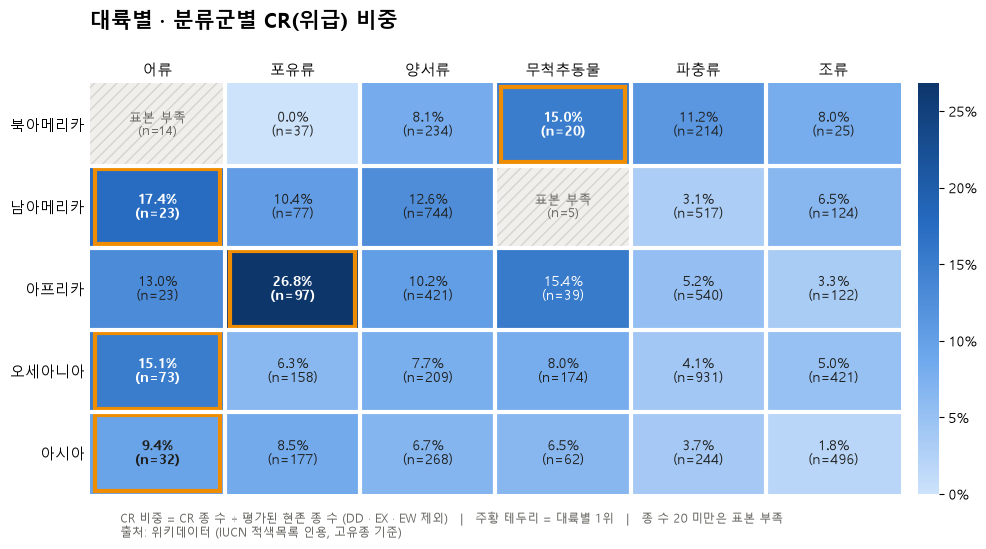

,1위 분류군,CR 비중,종 수
대륙,,,
북아메리카,무척추동물,15.0%,20
남아메리카,어류,17.4%,23
아프리카,포유류,26.8%,97
오세아니아,어류,15.1%,73
아시아,어류,9.4%,32


In [11]:
# ── 3-1. 대륙 × 분류군 CR 비중 히트맵 ─────────────────────────
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter

plt.rcParams["font.family"] = "Malgun Gothic"  # 한글 폰트 (Windows)
plt.rcParams["axes.unicode_minus"] = False

n = pd.crosstab(analysis["대륙"], analysis["분류군"])
cr = pd.crosstab(analysis["대륙"], analysis["분류군"], values=analysis["CR"], aggfunc="sum").fillna(0)
ratio = (cr / n).where(n >= MIN_N)  # 표본 부족 칸은 NaN

# 대륙 · 분류군 모두 전체 CR 비중이 높은 순으로 정렬 → 진한 칸이 왼쪽 위로 모인다
row_order = analysis.groupby("대륙")["CR"].mean().sort_values(ascending=False).index
col_order = analysis.groupby("분류군")["CR"].mean().sort_values(ascending=False).index
n, ratio = n.loc[row_order, col_order], ratio.loc[row_order, col_order]

# 파란색 한 가지의 연한 → 진한 단계: 진할수록 CR 비중이 높다
cmap = LinearSegmentedColormap.from_list("cr", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
vmax = ratio.max().max()

fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(ratio.values, cmap=cmap, vmin=0, vmax=vmax, aspect="auto")

top = ratio.idxmax(axis=1)  # 대륙별 1위 분류군
for i, cont in enumerate(row_order):
    for j, grp in enumerate(col_order):
        v, cnt = ratio.iat[i, j], n.iat[i, j]
        if pd.isna(v):  # 표본 부족: 회색 빗금 + 종 수만 표시
            ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, facecolor="#f0efec",
                                   hatch="///", edgecolor="#d6d4ce", lw=0))
            ax.text(j, i, f"표본 부족\n(n={cnt})", ha="center", va="center", fontsize=9, color="#6b6a66")
            continue
        is_top = grp == top[cont]
        ax.text(j, i, f"{v:.1%}\n(n={cnt})", ha="center", va="center", fontsize=10,
                color="white" if v > vmax * 0.5 else "#1f1f1d", fontweight="bold" if is_top else "normal")
        if is_top:  # 대륙별 1위 칸 테두리
            ax.add_patch(Rectangle((j - .46, i - .46), .92, .92, fill=False, edgecolor="#f08c00", lw=3))

# 칸 사이 흰 간격
ax.set_xticks(range(len(col_order)), col_order, fontsize=11)
ax.set_yticks(range(len(row_order)), row_order, fontsize=11)
ax.set_xticks([x - .5 for x in range(1, len(col_order))], minor=True)
ax.set_yticks([y - .5 for y in range(1, len(row_order))], minor=True)
ax.grid(which="minor", color="white", lw=3)
ax.tick_params(which="both", length=0)
ax.xaxis.tick_top()
for s in ax.spines.values():
    s.set_visible(False)

cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02, format=PercentFormatter(1, decimals=0))
cbar.outline.set_visible(False)

ax.set_title("대륙별 · 분류군별 CR(위급) 비중", fontsize=15, fontweight="bold", loc="left", pad=40)
fig.text(0.125, 0.015,
         f"CR 비중 = CR 종 수 ÷ 평가된 현존 종 수 (DD · EX · EW 제외)   |   주황 테두리 = 대륙별 1위   |   "
         f"종 수 {MIN_N} 미만은 표본 부족\n출처: 위키데이터 (IUCN 적색목록 인용, 고유종 기준)",
         fontsize=8.5, color="#6b6a66")
plt.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(Path.cwd() / "CR비중_히트맵.png", dpi=200, bbox_inches="tight")
plt.show()

# 대륙별 1위 요약표
best = pd.DataFrame({"1위 분류군": top, "CR 비중": ratio.max(axis=1).map("{:.1%}".format),
                     "종 수": [n.loc[c, top[c]] for c in row_order]})
display(best)

### 3-2. 막대그래프: 95% 신뢰구간은 이렇게 구했다

막대 길이는 3-1과 같은 CR 비중이다. 여기에 **이 비율을 얼마나 믿을 수 있는지** 보여 주는 검은 선(95% 신뢰구간)을 더했다.

**왜 필요한가?**

같은 15%라도 믿을 수 있는 정도가 다르다.
- 20종 중 3종: CR이 1종만 달라져도 10% 또는 20%가 된다 → 불확실
- 2,000종 중 300종: 몇 종이 달라져도 15% 근처 → 믿을 만함

**윌슨(Wilson) 신뢰구간 공식** (`wilson_ci` 함수)

```
p = k / n   (k = CR 종 수, n = 전체 종 수, z = 1.96 ← 95%)

중심 = (p + z²/2n) ÷ (1 + z²/n)
반폭 = z × √( p(1-p)/n + z²/4n² ) ÷ (1 + z²/n)
신뢰구간 = 중심 - 반폭 ~ 중심 + 반폭
```

> 예) 아프리카 포유류 (k = 26, n = 97)
> 1. p = 26 ÷ 97 = 0.268
> 2. 중심 = (0.268 + 0.0198) ÷ 1.0396 = 0.277
> 3. 반폭 = 1.96 × √(0.00202 + 0.00010) ÷ 1.0396 = 0.087
> 4. 신뢰구간 = **19.0% ~ 36.4%**

n이 클수록 반폭이 작아진다. 그래서 남아메리카 양서류(744종)는 선이 짧고, 남아메리카 어류(23종)는 선이 길다.

**왜 기본 공식(p ± 1.96 × 표준오차) 대신 윌슨을 썼나?**

기본 공식은 표본이 작거나 비율이 0%에 가까우면 잘못된 값이 나온다.

| 예: 북아메리카 포유류 (0 / 37종) | 신뢰구간 | 의미 |
|---|---|---|
| 기본 공식 | 0% ~ 0% | "확실히 0%" → 잘못된 결론 |
| 윌슨 | **0% ~ 9.4%** | "37종만으로는 최대 9% 정도일 수도 있다" |

이번 데이터는 20 ~ 30종짜리 칸이 많아서 윌슨이 더 적합하다.

**'확실한 1위' 판단 기준** (그래프 아래 표)

```
1위 신뢰구간의 하한 > 2위 신뢰구간의 상한  →  "확실한 1위"
두 구간이 겹치면                          →  "2위와 차이 불확실"
```

- 아프리카: 포유류 하한 19.0% < 무척추동물 상한 29.7% → 겹침 → 불확실
- 하지만 포유류 하한 19.0% > 양서류 상한 약 13.5% → 양서류보다는 확실히 높다

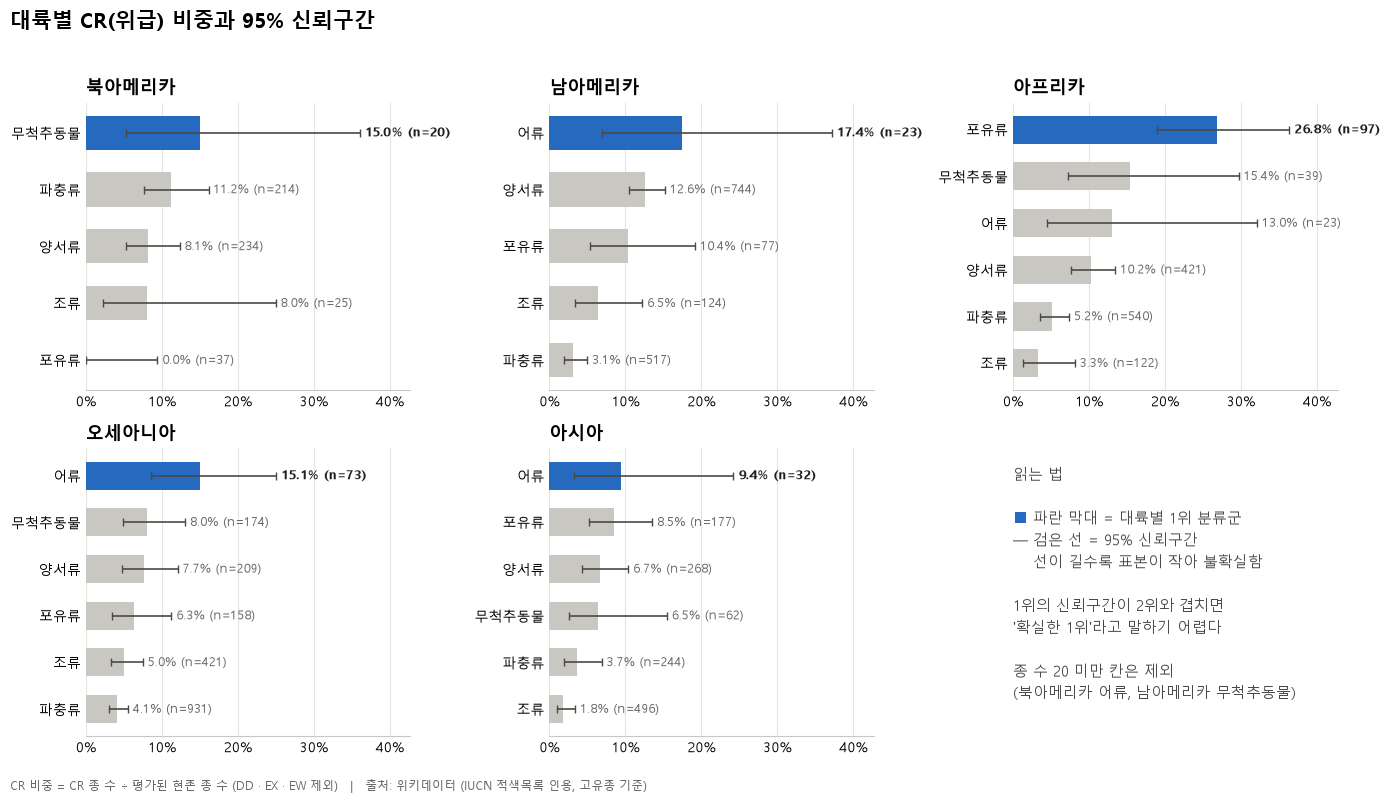

,1위,2위,판단
대륙,,,
북아메리카,무척추동물 15.0% (5.2%~36.0%),파충류 11.2% (7.7%~16.1%),2위와 차이 불확실
남아메리카,어류 17.4% (7.0%~37.1%),양서류 12.6% (10.4%~15.2%),2위와 차이 불확실
아프리카,포유류 26.8% (19.0%~36.4%),무척추동물 15.4% (7.2%~29.7%),2위와 차이 불확실
오세아니아,어류 15.1% (8.6%~25.0%),무척추동물 8.0% (4.9%~13.1%),2위와 차이 불확실
아시아,어류 9.4% (3.2%~24.2%),포유류 8.5% (5.2%~13.5%),2위와 차이 불확실


In [12]:
# ── 3-2. 대륙별 CR 비중 막대그래프 + 95% 신뢰구간 ───────────────
# 종 수가 적은 칸은 CR 1~2종 차이로 비중이 크게 흔들린다.
# 윌슨(Wilson) 95% 신뢰구간을 오차막대로 그려, 1위가 2위와 '확실히' 다른지 확인한다.
import numpy as np


def wilson_ci(k, n, z=1.96):
    """비율 k/n의 윌슨 95% 신뢰구간 (표본이 작거나 비율이 0에 가까워도 안정적)"""
    p = k / n
    center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return center - half, center + half


stats = (analysis.groupby(["대륙", "분류군"])["CR"].agg(CR수="sum", 종수="size").reset_index()
         .query("종수 >= @MIN_N"))  # 표본 부족 칸 제외
stats["CR비중"] = stats["CR수"] / stats["종수"]
stats["하한"], stats["상한"] = wilson_ci(stats["CR수"], stats["종수"])

order = analysis.groupby("대륙")["CR"].mean().sort_values(ascending=False).index  # 3-1과 같은 순서
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True)
xmax = stats["상한"].max() * 1.15

for ax, cont in zip(axes.flat, order):
    d = stats[stats["대륙"] == cont].sort_values("CR비중")  # 아래 → 위로 커지게 (1위가 맨 위)
    colors = ["#256abf" if i == len(d) - 1 else "#c9c7c1" for i in range(len(d))]
    y = np.arange(len(d))
    ax.barh(y, d["CR비중"], color=colors, height=0.6)
    ax.errorbar(d["CR비중"], y, xerr=[d["CR비중"] - d["하한"], d["상한"] - d["CR비중"]],
                fmt="none", ecolor="#4a4945", elinewidth=1.2, capsize=3)
    for yi, (_, r) in zip(y, d.iterrows()):
        ax.text(r["상한"] + xmax * 0.015, yi, f"{r['CR비중']:.1%} (n={r['종수']})", va="center",
                fontsize=9, color="#1f1f1d" if yi == len(d) - 1 else "#6b6a66",
                fontweight="bold" if yi == len(d) - 1 else "normal")
    ax.set_yticks(y, d["분류군"], fontsize=10)
    ax.set_title(cont, fontsize=13, fontweight="bold", loc="left")
    ax.set_xlim(0, xmax)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="x", color="#e6e4df", lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, labelbottom=True)  # 위 줄 그래프에도 x축 눈금 표시
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#c9c7c1")

# 남는 6번째 칸에 읽는 법 설명
guide = axes.flat[-1]
guide.axis("off")
guide.text(0, 0.95, "\n\n■", va="top", fontsize=10.5, color="#256abf", linespacing=1.5)  # 파란 네모
guide.text(0, 0.95,
           "읽는 법\n\n"
           "    파란 막대 = 대륙별 1위 분류군\n"
           "─ 검은 선 = 95% 신뢰구간\n"
           "    선이 길수록 표본이 작아 불확실함\n\n"
           "1위의 신뢰구간이 2위와 겹치면\n'확실한 1위'라고 말하기 어렵다\n\n"
           f"종 수 {MIN_N} 미만 칸은 제외\n"
           "(북아메리카 어류, 남아메리카 무척추동물)",
           va="top", fontsize=10.5, color="#4a4945", linespacing=1.5)

fig.suptitle("대륙별 CR(위급) 비중과 95% 신뢰구간", fontsize=15, fontweight="bold", x=0.01, ha="left")
fig.text(0.01, 0.005, "CR 비중 = CR 종 수 ÷ 평가된 현존 종 수 (DD · EX · EW 제외)   |   "
         "출처: 위키데이터 (IUCN 적색목록 인용, 고유종 기준)", fontsize=8.5, color="#6b6a66")
plt.tight_layout(rect=(0, 0.03, 1, 0.96))
fig.savefig(Path.cwd() / "CR비중_대륙별_막대.png", dpi=200, bbox_inches="tight")
plt.show()

# 1위가 2위보다 확실히 높은지: 1위의 신뢰구간 하한 > 2위의 신뢰구간 상한이면 '확실한 1위'
rows = []
for cont in order:
    d = stats[stats["대륙"] == cont].sort_values("CR비중", ascending=False)
    first, second = d.iloc[0], d.iloc[1]
    rows.append({"대륙": cont,
                 "1위": f"{first['분류군']} {first['CR비중']:.1%} ({first['하한']:.1%}~{first['상한']:.1%})",
                 "2위": f"{second['분류군']} {second['CR비중']:.1%} ({second['하한']:.1%}~{second['상한']:.1%})",
                 "판단": "확실한 1위" if first["하한"] > second["상한"] else "2위와 차이 불확실"})
display(pd.DataFrame(rows).set_index("대륙"))

### 3-3. 1위와 2위의 차이가 '불확실'하다고 본 이유

분석 질문이 **"어떤 분류군이 1위인가?"** 라서, 그 1위가 정말 1위인지 확인해야 한다.

**① 비율만 보면 1위는 항상 나온다**

비율을 정렬하면 차이가 아주 작아도 누군가는 1위가 된다. 그 1위가 진짜 차이 때문인지 우연 때문인지는 비율만으로 알 수 없다.

**② 이번 데이터에서는 1 ~ 2종만 달라져도 1위가 바뀐다**

대륙별 1위 5개 중 4개가 20 ~ 73종짜리 작은 칸이다.

| 대륙 | 지금 | CR이 조금 적었다면 |
|---|---|---|
| 아시아 | 어류 3 / 32 = 9.4% → **1위** | 1종 적으면 2 / 32 = 6.3% → **3위** (포유류 8.5%, 양서류 6.7%보다 낮음) |
| 남아메리카 | 어류 4 / 23 = 17.4% → **1위** | 2종 적으면 2 / 23 = 8.7% → **3위** (양서류 12.6%, 포유류 10.4%보다 낮음) |

위키데이터에 등급이 하나만 잘못 기록되거나 종 하나가 빠져도 **분석 질문의 답이 바뀔 수 있다.**

**③ 통계 검정으로도 확인: 피셔 정확 검정 (Fisher's exact test)**

신뢰구간이 겹치는지로 판단하는 방법은 보수적이라, 표본이 작을 때 쓰는 피셔 정확 검정으로 1위와 2위의 CR 비중 차이를 다시 확인했다 (`scipy.stats.fisher_exact`).
p값이 0.05보다 작아야 '우연이 아닌 차이'로 본다.

| 대륙 | 1위 (CR / 전체) | 2위 (CR / 전체) | p값 | 판단 |
|---|---|---|---|---|
| 오세아니아 | 어류 11 / 73 | 무척추동물 14 / 174 | 0.108 | 유의하지 않음 |
| 아프리카 | 포유류 26 / 97 | 무척추동물 6 / 39 | 0.185 | 유의하지 않음 |
| 남아메리카 | 어류 4 / 23 | 양서류 94 / 744 | 0.521 | 유의하지 않음 |
| 북아메리카 | 무척추동물 3 / 20 | 파충류 24 / 214 | 0.711 | 유의하지 않음 |
| 아시아 | 어류 3 / 32 | 포유류 15 / 177 | 0.743 | 유의하지 않음 |

5개 대륙 모두 p값이 0.05보다 커서 **신뢰구간으로 본 결과와 같다.**

**④ 그래서 이렇게 해석한다**

- '불확실'은 **"차이가 없다"가 아니라 "확실하다고 말하기엔 표본이 부족하다"** 는 뜻이다
- 이 점을 빼면 "아시아에서는 어류가 가장 위험하다"처럼 데이터가 뒷받침하지 못하는 결론이 된다
- 반대로 **확실하게 말할 수 있는 것**도 있다
  - 아프리카 포유류(26.8%)는 표본이 큰 양서류(10.2%) · 파충류(5.2%) · 조류(3.3%)보다 확실히 높다
  - 조류 · 파충류는 표본이 커서 '모든 대륙에서 CR 비중이 낮다'는 결과를 믿을 수 있다
- 표본을 늘리면(5번 섹션 IUCN API) 이 불확실성을 줄일 수 있다 → 4-4 극복 방안

## 4. 통합 리포트 🐒

### 4-1. 분석 개요

- **분석 질문**: 대륙별로 어떤 분류군의 CR(위급) 비중이 가장 높을까?
- **데이터**: 위키데이터에서 수집한 IUCN 적색목록 등급 + 고유 분포 국가(endemic to)로 정한 대륙 (최근 10년 이내 출처)
- **지표**: CR 비중 = CR 종 수 ÷ 평가된 현존 종 수
  - DD(정보 부족) 제외: 실제 위험도를 알 수 없어서
  - EX · EW(멸종 · 야생 멸종) 제외: 이미 사라진 종이라 CR이 될 수 없어서
- **비교 단위**: 대륙 5개 × 분류군 6개 = 30칸. 종 수 20 미만 칸은 '표본 부족'으로 비교에서 뺀다

### 4-2. 데이터 정제 요약

| 단계 | 행 수 | 내용 |
|---|---|---|
| 1. 수집 | 8,614 | 종 × 대륙 (위키데이터) |
| 2-1 ~ 2-5. 정제 | 7,429 | 중복 제거, 여러 대륙에 걸친 종 → 대륙 1개, 동물만 남김, 표기 · 아종 통일, 남극 제외 |
| 2-7. 분석 범위 정리 | **6,521** | DD · EX · EW 882종 제외, 유럽 26종 제외, 무척추동물 6개 분류군 → 1개로 묶음 |

- 최종 분석 데이터: `멸종위기_동물_분석용.csv` (CR 462종, 전체 CR 비중 **7.1%**)
- 표본 부족 칸: 2 / 30칸 (북아메리카 어류 14종, 남아메리카 무척추동물 5종)

### 4-3. 주요 결과

**대륙별 CR 비중 1위 분류군** (3-1 히트맵 · 3-2 막대그래프)

| 대륙 | 1위 분류군 | CR 비중 | 종 수 | 95% 신뢰구간 | 2위와 비교 |
|---|---|---|---|---|---|
| 아프리카 | 포유류 | **26.8%** | 97 | 19.0 ~ 36.4% | 차이 불확실 |
| 남아메리카 | 어류 | 17.4% | 23 | 7.0 ~ 37.1% | 차이 불확실 |
| 오세아니아 | 어류 | 15.1% | 73 | 8.6 ~ 25.0% | 차이 불확실 |
| 북아메리카 | 무척추동물 | 15.0% | 20 | 5.2 ~ 36.0% | 차이 불확실 |
| 아시아 | 어류 | 9.4% | 32 | 3.2 ~ 24.2% | 차이 불확실 |

**발견한 점**

1. **아프리카 포유류가 가장 두드러진다 (26.8%)**
   - 30칸 중 가장 높고, 전체 평균(7.1%)의 약 3.8배
   - 신뢰구간 하한(19.0%)이 표본이 충분한 양서류(10.2%, 421종) · 파충류(5.2%, 540종) · 조류(3.3%, 122종)의 신뢰구간보다 위에 있어 확실히 높다
   - 2위 무척추동물(15.4%, 39종)과는 신뢰구간이 겹치는데, 무척추동물의 표본이 작아 구간이 넓기 때문이다
2. **어류가 3개 대륙(남아메리카 · 오세아니아 · 아시아)에서 1위**
   - 전체 기준으로도 어류의 CR 비중이 15.2%로 가장 높다
   - 다만 어류는 전체의 2.5%(165종)뿐이라 대륙별로 23 ~ 73종 → 순위가 바뀔 수 있다
3. **조류 · 파충류는 모든 대륙에서 CR 비중이 낮다** (전체 기준 조류 3.7%, 파충류 4.7%)
   - 표본이 크고(조류 1,188종, 파충류 2,446종) 신뢰구간이 좁아 믿을 만한 결과다
4. **대륙 전체로 보면** 북아메리카(9.6%) > 남아메리카 · 아프리카(8.9%) > 오세아니아(5.6%) > 아시아(4.5%)
5. 북아메리카 포유류는 37종 중 CR이 0종이다

### 4-4. 한계점과 극복 방안

이번 분석은 위키데이터로 수집한 데이터를 사용해서, 수집 · 정제 · 분석 과정마다 한계가 있었다.

**① 표본이 부족해서 분석에서 뺀 것**

| 제외한 것 | 규모 | 이유 · 영향 |
|---|---|---|
| 남극 | 1종 | 다른 대륙과 비교할 수 없음 |
| 유럽 | 26종 (등급 정리 전 28종) | 6개 분류군 모두 20종 미만이라 비교할 칸이 없음 |
| 표본 부족 칸 | 북아메리카 어류 14종, 남아메리카 무척추동물 5종 | 종 수 20 미만이라 CR 비중을 계산하지 않음 |
| DD(정보 부족) | 803종 (동물의 10.8%) | 위험도를 알 수 없어 제외. DD 중 실제 CR인 종이 있다면 CR 비중이 낮게 나왔을 수 있음 |

**② 데이터 수집 방식에서 생긴 한계**

1. **고유종만 들어 있다**: 위키데이터에서는 고유 분포 국가(P183)가 기록된 종만 대륙을 알 수 있다. 여러 나라 · 대륙에 넓게 사는 종은 대부분 빠졌고, 유럽 · 남극의 종 수가 적은 것도 이 때문이다. 파충류(37.5%)와 양서류(28.8%)가 전체의 66%를 차지해, 각 대륙의 전체 동물을 대표하지 못한다.
2. **여러 대륙에 걸친 22종을 대륙 1개로 정했다**: 모식 산지가 기록된 종이 0종이어서 첫 번째 규칙은 쓰이지 못했고, '대륙 걸침 국가 규칙'과 '분포 국가 수'로 판단했다. 분석하는 사람의 판단이 들어간 부분이다.
3. **수집 단계에서 빠진 행**: 대륙이 애매한 8행, 출처연도가 2016년 미만이거나 없는 40행을 제외했다.
4. **출처연도 ≠ 평가연도**: `출처연도`는 위키데이터 출처의 날짜이고 79%가 2022년이라, 시기별 변화(위험도가 나빠지는지)는 분석할 수 없었다.
5. **분류군 정보가 불완전하다**: 위키데이터의 분류 체계를 30단계 넘게 거슬러 올라가 분류군을 정했고, 끝까지 분류되지 않은 5종은 '기타'로 남았다.
6. **종 이름이 부족하다**: 한글 이름이 있는 종은 11.5%뿐이고 63%는 학명만 있다. 결과를 설명할 때 구체적인 종 예시를 들기 어렵다.
7. **아종 통합**: 4종의 아종 9행을 종 단위로 합칠 때 가장 위급한 등급을 남겨서, CR이 조금 많게 집계됐을 수 있다 (영향은 작음).

**③ 분석 결과의 한계**

1. **1위와 2위의 차이가 불확실하다**: 대륙별 1위 5개 중 4개가 20 ~ 73종이라 신뢰구간이 넓다. 5개 대륙 모두 1위와 2위의 차이가 통계적으로 확실하지 않아, 순위는 '경향'으로만 해석할 수 있다.
2. **무척추동물을 하나로 묶었다**: 표본을 확보하려고 곤충 · 갑각류 · 연체동물 등 6개 분류군을 합쳐서 세부 차이는 볼 수 없다.
3. **북아메리카 포유류 CR 0종 (37종 중)**: 실제로 위급한 종이 없는 것인지, 데이터에서 빠진 것인지 이 데이터만으로는 확인할 수 없다.
4. **위키데이터 기록 품질**: 위키데이터는 누구나 편집할 수 있어 IUCN 공식 데이터와 다를 수 있다.

**④ 극복 방안: 5번 (선택) 섹션의 IUCN API로 다시 수집하기**

5번 섹션은 IUCN 적색목록 공식 API로 **각 나라에 서식하는 모든 평가종**을 받아 대륙별로 다시 만든다. 이 섹션을 실행하면 위 한계 대부분을 줄일 수 있다.

| 지금의 한계 | API로 다시 수집하면 |
|---|---|
| 고유종만 있어 표본이 적음 | 나라별 서식종을 모두 받아 **표본이 크게 늘어남** |
| 유럽 제외 | 유럽도 비교할 수 있음 (남극은 서식 종 자체가 적어 여전히 어려울 수 있음) |
| 표본이 작아 1 · 2위 차이가 불확실 | 신뢰구간이 좁아져 '확실한 1위'인지 판단할 수 있음 |
| 여러 대륙에 걸친 종을 1개 대륙으로 판단 | 대륙마다 1행으로 집계해 판단 규칙이 필요 없음 |
| 출처연도 ≠ 평가연도 | IUCN이 실제로 평가를 발표한 연도(`year_published`)를 사용 |
| 분류군 추적이 불완전 · 무척추동물을 묶음 | 강(class)별 목록으로 바로 연결, 표본이 늘면 무척추동물도 나눠 볼 수 있음 |
| 위키데이터 기록 품질 | IUCN 공식 데이터 사용 |

API를 쓸 때 주의할 점
- IUCN 계정과 API 토큰이 필요하다 (무료, 비상업 용도만 가능)
- 나라 약 250개를 받느라 **1시간 이상** 걸린다 (중간에 끊겨도 `iucn_cache` 폴더로 이어서 받을 수 있음)
- 대륙 기준이 UN M49 지역 분류라서 (예: 러시아 → 유럽, 멕시코 → 북아메리카) 위키데이터 결과와 그대로 비교하면 안 된다
- 한 종이 여러 대륙에 살면 대륙마다 집계된다
- DD(정보 부족) 문제는 API로도 해결되지 않는다
- 아직 실행해 보지 않았으므로, 표본이 실제로 얼마나 늘어나는지는 실행해 봐야 알 수 있다

### 4-5. 결론

> **대륙별로 CR(위급) 비중이 가장 높은 분류군은 아프리카의 포유류(26.8%)가 가장 두드러졌고,
> 나머지 대륙에서는 어류(남아메리카 · 오세아니아 · 아시아)와 무척추동물(북아메리카)이 1위였다.**

- **확실하게 말할 수 있는 것**
  - 아프리카 포유류는 4종 중 1종 이상이 위급(CR) 단계로, 다른 대륙 · 분류군보다 뚜렷하게 높다
  - 조류 · 파충류는 모든 대륙에서 CR 비중이 낮다
- **조심해서 말해야 하는 것**
  - 어류 · 무척추동물의 1위는 표본이 작아 '경향' 수준이다
- **다음 단계**
  - 4-4의 극복 방안처럼 5번 (선택) 섹션의 IUCN API로 각 나라에 서식하는 모든 평가종을 다시 수집하면,
    유럽까지 포함하고 표본을 늘려 이번 결과(특히 표본이 작았던 어류 · 무척추동물의 1위)를 검증할 수 있다

## 5. (선택 · 현재 분석에는 사용 안 함) IUCN 적색목록 API로 다시 수집하기

> 수집에 1시간 이상 걸려서 이번 분석은 위키데이터 데이터(2번 섹션)로 진행한다.
> 나중에 데이터를 늘리고 싶을 때 이 섹션을 실행한다.
>
> ⚠️ Run All 때 같이 실행되지 않도록 아래 코드 셀(5-1 ~ 5-5)은 전부 `#`으로 주석 처리해 두었다.
> 실행하려면 셀 안에서 전체 선택(Ctrl+A) 후 Ctrl+/ 를 눌러 주석을 푼다.

위키데이터는 '고유종'만 대륙 정보가 있어서 유럽(28종) · 남극(1종)이 너무 적었다.
IUCN 공식 API로 **각 나라에 서식하는 모든 평가종**을 받아 대륙별로 다시 만든다.

- 준비: https://api.iucnredlist.org 에서 계정을 만들고 API 토큰 발급 (무료 · 비상업 용도)
- 토큰은 실행할 때 입력창에 붙여 넣는다 (노트북에 적지 않기)
- 시간: 나라 약 250개 × 여러 페이지라 **1시간 이상** 걸릴 수 있음. 받은 결과는 `iucn_cache` 폴더에 저장되므로 중간에 끊겨도 다시 실행하면 이어서 받는다
- 결과: `IUCN_동물_종별_대륙.csv` — 종 × 대륙 (한 종이 여러 대륙에 살면 대륙마다 1행)
- `평가연도`는 IUCN이 실제 평가를 발표한 연도 (위키데이터의 '출처 연도'와 다름)

대륙 기준: UN M49 지역 분류 (나라마다 대륙 1개)

In [13]:
# # ── 5-1. API 준비 · 연결 테스트 ─────────────────────────────
# import os
# import time
# from getpass import getpass
# from pathlib import Path
#
# import pandas as pd
# import requests
#
# API = "https://api.iucnredlist.org/api/v4/"
# # 토큰은 노트북에 직접 적지 말 것 (공유 · 깃허브 업로드 시 노출됨)
# TOKEN = os.environ.get("IUCN_TOKEN") or getpass("IUCN API 토큰 입력: ")
# session = requests.Session()
# session.headers.update({"Authorization": f"Bearer {TOKEN}", "User-Agent": "DI2-EDA-student/1.0"})
#
# CACHE = Path.cwd() / "iucn_cache"
# CACHE.mkdir(exist_ok=True)
# OUT_DIR = Path.cwd()
#
# # 최근 10년 이내 평가만 사용. API는 연도 '범위'로 거르는 기능이 없어서
# # 받은 직후에 걸러서 저장한다 (저장 용량 · 메모리 절약)
# MIN_YEAR = pd.Timestamp.now().year - 10
# KEEP_COLS = ["sis_taxon_id", "taxon_scientific_name", "red_list_category_code", "year_published"]
#
#
# def api_get(path, params=None, retries=5):
#     """IUCN API GET. 요청이 많다는 응답(429)이나 서버 오류면 기다렸다가 재시도"""
#     for i in range(retries):
#         res = session.get(API + path, params=params, timeout=60)
#         if res.status_code == 429 or res.status_code >= 500:
#             wait = int(res.headers.get("Retry-After", 10 * (i + 1)))
#             print(f"  {res.status_code} → {wait}초 대기 후 재시도")
#             time.sleep(wait)
#             continue
#         if res.status_code == 401:
#             raise PermissionError("토큰이 잘못됐거나 아직 활성화되지 않았어요 (401)")
#         res.raise_for_status()
#         time.sleep(0.3)  # 서버 부담을 줄이기 위한 간격
#         return res.json()
#     raise RuntimeError(f"요청 실패: {path}")
#
#
# def fetch_all_cached(path, params, cache_name):
#     """100건씩 나뉜 페이지를 끝까지 받아, 최근 10년 평가 · 필요한 열만 남겨 CSV로 저장 · 재사용"""
#     f = CACHE / f"{cache_name}.csv"
#     if f.exists():
#         return pd.read_csv(f, dtype=str)
#     rows, page = [], 1
#     while True:
#         items = api_get(path, {**params, "page": page}).get("assessments", [])
#         rows += [{k: item.get(k) for k in KEEP_COLS} for item in items
#                  if int(item.get("year_published") or 0) >= MIN_YEAR]
#         if len(items) < 100:
#             break
#         page += 1
#     df = pd.DataFrame(rows, columns=KEEP_COLS).astype(str)
#     df.to_csv(f, index=False, encoding="utf-8-sig")
#     return df
#
#
# # 연결 테스트: 적색목록 버전 + 한국(KR) 첫 페이지 구조 확인
# print("적색목록 버전:", api_get("information/red_list_version"))
# sample = api_get("countries/KR", {"latest": "true", "scope_code": 1, "page": 1})
# print("응답 키:", list(sample.keys()))
# sample_df = pd.json_normalize(sample["assessments"])
# print("평가 항목 열:", sample_df.columns.tolist())
# display(sample_df.head())
#
# assert set(KEEP_COLS) <= set(sample_df.columns), \
#     f"필요한 열이 없음: {set(KEEP_COLS) - set(sample_df.columns)} → 열 이름을 알려주세요"
# recent = pd.to_numeric(sample_df["year_published"], errors="coerce") >= MIN_YEAR
# print(f"한국 첫 페이지 중 {MIN_YEAR}년 이후 평가: {recent.mean():.0%}")

In [14]:
# # ── 5-2. 나라 코드 → 대륙 (UN M49 지역 분류) ────────────────
# # 나라마다 대륙 1개가 정해져 있다. 예) 러시아 → 유럽, 튀르키예 · 키프로스 → 아시아,
# # 프랑스령 남방 지역 → 아프리카, 멕시코 · 중미 · 카리브 → 북아메리카
# m49 = pd.read_csv(
#     "https://raw.githubusercontent.com/lukes/ISO-3166-Countries-with-Regional-Codes/master/all/all.csv",
#     keep_default_na=False)  # 나미비아 코드 'NA'가 결측으로 읽히지 않도록
#
# # 분류표에 지역이 비어 있는 나라는 직접 지정
# MANUAL = {"AQ": "남극", "TW": "아시아"}
#
#
# def to_continent(row):
#     if row["alpha-2"] in MANUAL:
#         return MANUAL[row["alpha-2"]]
#     if row["region"] == "Americas":
#         return "남아메리카" if row["intermediate-region"] == "South America" else "북아메리카"
#     return {"Asia": "아시아", "Africa": "아프리카", "Europe": "유럽", "Oceania": "오세아니아"}.get(row["region"])
#
#
# m49["대륙"] = m49.apply(to_continent, axis=1)
# print("대륙이 정해지지 않은 나라:", m49.loc[m49["대륙"].isna(), "name"].tolist())
# cont_map = m49.dropna(subset=["대륙"])[["alpha-2", "name", "대륙"]]
# display(cont_map["대륙"].value_counts())

In [15]:
# # ── 5-3. 나라별 평가 목록 수집 (가장 오래 걸림) ─────────────────
# # 나라마다 그 나라에 서식하는 종의 최신 '전 지구(Global)' 평가 목록을 받는다.
# # 나라별로 iucn_cache 폴더에 저장하므로, 중간에 끊겨도 다시 실행하면 이어서 받는다.
# frames = []
# codes = cont_map["alpha-2"].tolist()
# for i, code in enumerate(codes, 1):
#     try:
#         d = fetch_all_cached(f"countries/{code}", {"latest": "true", "scope_code": 1}, f"country_{code}")
#     except requests.HTTPError as e:
#         if e.response is not None and e.response.status_code == 404:
#             continue  # IUCN에 없는 나라 코드
#         raise
#     d["country"] = code
#     frames.append(d)
#     if i % 10 == 0 or i == len(codes):
#         print(f"[{i}/{len(codes)}] 누적 {sum(len(f) for f in frames)}건")
# country_df = pd.concat(frames, ignore_index=True)
# print(f"나라 × 평가 {len(country_df)}건")

In [16]:
# # ── 5-4. 동물 분류군(강)별 평가 목록 → 종마다 분류군 붙이기 ──────
# # 나라별 목록에는 분류 정보가 없어서, 강(class)별 목록을 받아 sis_taxon_id로 연결한다.
# # 여기 없는 강(식물 · 균류 등)은 자동으로 빠진다.
# ANIMAL_CLASSES = {
#     "Mammalia": "포유류", "Aves": "조류", "Reptilia": "파충류", "Amphibia": "양서류",
#     "Actinopterygii": "어류", "Chondrichthyes": "어류", "Sarcopterygii": "어류",
#     "Myxini": "어류", "Cephalaspidomorphi": "어류",
#     "Insecta": "곤충", "Arachnida": "거미류", "Chilopoda": "기타 무척추동물", "Diplopoda": "기타 무척추동물",
#     "Malacostraca": "갑각류", "Branchiopoda": "갑각류", "Maxillopoda": "갑각류", "Ostracoda": "갑각류",
#     "Gastropoda": "연체동물", "Bivalvia": "연체동물", "Cephalopoda": "연체동물",
#     "Anthozoa": "자포동물", "Hydrozoa": "자포동물",
#     "Clitellata": "환형동물", "Polychaeta": "환형동물",
#     "Onychophora": "기타 무척추동물", "Holothuroidea": "기타 무척추동물", "Enopla": "기타 무척추동물",
# }
#
# frames = []
# for i, (cls, group) in enumerate(ANIMAL_CLASSES.items(), 1):
#     try:
#         d = fetch_all_cached(f"taxa/class/{cls}", {"latest": "true", "scope_code": 1}, f"class_{cls}")
#     except requests.HTTPError as e:
#         if e.response is not None and e.response.status_code == 404:
#             print(f"  {cls}: IUCN에 없는 강 이름 → 건너뜀")
#             continue
#         raise
#     d["강"], d["분류군"] = cls, group
#     frames.append(d)
#     print(f"[{i}/{len(ANIMAL_CLASSES)}] {cls}: {len(d)}건")
# class_df = pd.concat(frames, ignore_index=True)
# print(f"동물 평가 {len(class_df)}건")
# display(class_df["분류군"].value_counts())

In [17]:
# # ── 5-5. 합치기 · 정제 후 저장 ─────────────────────────────
# # 최근 10년 필터(MIN_YEAR)는 5-1의 수집 단계에서 이미 적용됨
# occ = country_df.merge(cont_map, left_on="country", right_on="alpha-2")[
#     ["sis_taxon_id", "taxon_scientific_name", "red_list_category_code", "year_published", "대륙"]]
# data = occ.merge(class_df[["sis_taxon_id", "분류군", "강"]].drop_duplicates("sis_taxon_id"), on="sis_taxon_id")
# print(f"동물 · 나라 기록: {len(data)}행")
#
# data = data.rename(columns={"taxon_scientific_name": "학명", "red_list_category_code": "IUCN등급",
#                             "year_published": "평가연도"})
# data["학명"] = data["학명"].str.normalize("NFC").str.strip().str.replace(r"\s+", " ", regex=True)
# data["평가연도"] = pd.to_numeric(data["평가연도"], errors="coerce").astype("Int64")
#
# # 종 단위만 남김 (아종 · 지역개체군처럼 학명이 3단어 이상인 평가 제외)
# infra = data["학명"].str.split().str.len() > 2
# print(f"아종 · 지역개체군 평가 제외: {data.loc[infra, 'sis_taxon_id'].nunique()}종")
# data = data[~infra]
#
# # 한 종이 같은 대륙의 여러 나라에 있으면 1행으로 (종 × 대륙)
# data = data.drop_duplicates(["sis_taxon_id", "대륙"])
# print(f"종 × 대륙: {len(data)}행, 종 {data['sis_taxon_id'].nunique()}개 "
#       f"(평가연도 {data['평가연도'].min()}~{data['평가연도'].max()})")
#
# data = data[["sis_taxon_id", "학명", "분류군", "강", "IUCN등급", "평가연도", "대륙"]] \
#     .sort_values(["대륙", "분류군", "학명"]).reset_index(drop=True)
# data.to_csv(OUT_DIR / "IUCN_동물_종별_대륙.csv", index=False, encoding="utf-8-sig")
# print(f"저장 완료: IUCN_동물_종별_대륙.csv ({len(data)}행)")
# display(pd.crosstab(data["대륙"], data["분류군"], margins=True, margins_name="합계"))